## Setup

In [126]:
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import ExifTags, Image, ImageDraw
from tqdm.auto import tqdm

In [127]:
DATA_DIR = Path("../data")
IMAGE_EXT = ".jpg"

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
splits = {"train": train, "test": test}

## 1. Files

### Open every image
For each `image_id` from the csv: does the file exist, its size in bytes, does it decode, its real format, colour mode, width and height, and EXIF (tag count, capture date, camera model).

In [128]:
def image_path(split: str, image_id: str) -> Path:
    return DATA_DIR / split / f"{image_id}{IMAGE_EXT}"


def light_stats(im: Image.Image) -> dict:
    px = np.asarray(im.convert("L"), dtype=float) / 255
    return {"brightness": px.mean(), "contrast": px.std()}


assert light_stats(Image.new("L", (2, 2), 0)) == {"brightness": 0, "contrast": 0}
assert light_stats(Image.new("L", (2, 2), 255)) == {"brightness": 1, "contrast": 0}
assert light_stats(Image.fromarray(np.array([[0, 255], [255, 0]], dtype=np.uint8))) == {"brightness": .5, "contrast": .5}


def decode(path: Path) -> dict:
    """Fully decode the image: load() also catches truncated files that verify() misses."""
    try:
        with Image.open(path) as im:
            im.load()
            exif = im.getexif()
            return {
                "ok": True, "format": im.format, "mode": im.mode, "w": im.width, "h": im.height,
                "exif": len(exif),  # number of EXIF tags, 0 = none
                "date": exif.get_ifd(ExifTags.IFD.Exif).get(ExifTags.Base.DateTimeOriginal),
                "camera": exif.get(ExifTags.Base.Model),
                **light_stats(im),
            }
    except Exception:  
        return {"ok": False}


def image_info(path: Path) -> dict:
    if not path.exists():
        return {"exists": False, "ok": False}
    return {"exists": True, "bytes": path.stat().st_size, **decode(path)}

In [129]:
META_COLUMNS = ["image_id", "exists", "bytes", "ok", "format", "mode", "w", "h", "exif", "date", "camera", "brightness", "contrast"]


def scan_split(split: str, ids: pd.Series) -> pd.DataFrame:
    records = [{"image_id": i, **image_info(image_path(split, i))} for i in tqdm(ids, desc=split)]
    return pd.DataFrame(records, columns=META_COLUMNS)


meta = {split: scan_split(split, df.image_id) for split, df in splits.items()}

train:   0%|          | 0/12260 [00:00<?, ?it/s]

test:   0%|          | 0/18673 [00:00<?, ?it/s]

### Missing, extra and broken files

In [130]:
def integrity(split: str) -> dict:
    m, ids = meta[split], splits[split].image_id
    on_disk = {p.stem for p in (DATA_DIR / split).glob(f"*{IMAGE_EXT}")}
    return {
        "csv rows": len(ids),
        "files on disk": len(on_disk),
        "duplicate ids": ids.duplicated().sum(),
        "ids without file": (~m.exists).sum(),
        "files not in csv": len(on_disk - set(ids)),
        "empty files (0 bytes)": (m.bytes == 0).sum(),
        "corrupt / unreadable": (m.exists & ~m.ok).sum(),
    }


summary = pd.DataFrame({split: integrity(split) for split in splits})
summary

,train,test
csv rows,12260,18673
files on disk,12260,18673
duplicate ids,0,0
ids without file,0,0
files not in csv,0,0
empty files (0 bytes),0,0
corrupt / unreadable,0,0


### Colour modes

In [131]:
modes = pd.DataFrame({split: m["mode"].value_counts(dropna=False) for split, m in meta.items()}).fillna(0).astype(int)
modes.index.name = "mode"
modes

,train,test
mode,,
RGB,12260,18673


### Problem files

In [132]:
problems = pd.concat(
    [m.assign(split=split) for split, m in meta.items()]
).query("not exists or bytes == 0 or not ok")
problems

,image_id,exists,bytes,ok,format,mode,w,h,exif,date,camera,brightness,contrast,split


### Image sizes

In [133]:
images = pd.concat([m.assign(split=split) for split, m in meta.items()], ignore_index=True).query("ok")
sizes = pd.crosstab([images.w.astype(int), images.h.astype(int)], images.split)
sizes

,split,test,train
w,h,,
450,375,18673,12260


### Format

In [134]:
pd.crosstab(images.format, images.split)[list(splits)]

split,train,test
format,,
JPEG,12260,18673


### EXIF
Number of images with any EXIF tag, with a capture date and with a camera model.

In [135]:
pd.DataFrame({
    "any EXIF": images.exif > 0,
    "capture date": images.date.notna(),
    "camera model": images.camera.notna(),
}).groupby(images.split).sum().T[list(splits)]

split,train,test
any EXIF,0,0
capture date,0,0
camera model,0,0


Our dataset is beautiful, very beautiful, it is the best dataset I have ever seen

## 2. Labels

In [136]:
LABELS = ["Cat", "Dog", "Moris", "Motya", "Biatrix"]
y = train[LABELS]
assert y.isin([0, 1]).all().all()

### Class counts

In [137]:
pd.DataFrame({"count": y.sum(), "share": y.mean().round(3)})

,count,share
Cat,5077,0.414
Dog,5025,0.410
Moris,56,0.005
Motya,42,0.003
Biatrix,41,0.003


### Labels per image
Row `0` = images without any label. 

In [138]:
labelled = {split: df[LABELS] for split, df in splits.items() if set(LABELS) <= set(df.columns)}
counts = pd.DataFrame({split: lab.sum(axis=1).value_counts() for split, lab in labelled.items()}).fillna(0).astype(int).sort_index()
counts.index.name = "labels per image"
pd.concat({"images": counts, "share": (counts / counts.sum()).round(3)}, axis=1)

,images,share
,train,train
labels per image,,
0,2162,0.176
1,9973,0.813
2,111,0.009
3,10,0.001
4,4,0.000


### Co-occurrence
Diagonal = class count, off-diagonal = how often two classes appear on the same image.

In [139]:
y.T @ y

,Cat,Dog,Moris,Motya,Biatrix
Cat,5077,4,56,42,4
Dog,4,5025,4,0,41
Moris,56,4,56,10,4
Motya,42,0,10,42,0
Biatrix,4,41,4,0,41


Classes are almost disjoint сat and dog appear together on only 4 images.
Moris and Motya appear together on 10 images; Motya never appears with Dog or Biatrix.


Exact label combinations:

In [140]:
y.value_counts()

Cat  Dog  Moris  Motya  Biatrix
1    0    0      0      0          4989
0    1    0      0      0          4984
     0    0      0      0          2162
1    0    1      0      0            42
0    1    0      0      1            37
1    0    0      1      0            32
          1      1      0            10
     1    1      0      1             4
Name: count, dtype: int64

Data have 8 different posible combinations. The only when there is a cat and dog is with Moris and Biatrix 

### Label logic
Every Moris and Motya must also be a Cat, every Biatrix a Dog.

In [141]:
rules = {
    "Moris without Cat": (y.Moris == 1) & (y.Cat == 0),
    "Motya without Cat": (y.Motya == 1) & (y.Cat == 0),
    "Biatrix without Dog": (y.Biatrix == 1) & (y.Dog == 0),
}
pd.Series({name: mask.sum() for name, mask in rules.items()}, name="violations")

Moris without Cat      0
Motya without Cat      0
Biatrix without Dog    0
Name: violations, dtype: int64

In [142]:
train[pd.concat(rules, axis=1).any(axis=1)]

,image_id,Cat,Dog,Moris,Motya,Biatrix


Beautiful, very beautiful

The Cat and Dog classes are balanced with each other. Named animals are rare: Moris — 56, Motya — 42, Biatrix — 41 photos. Another 2162 photos have no labels at all.

Only photos with named animals have more than one label, because such an animal is always labeled together with its species (e.g., Moris + Cat). A cat and a dog appear together in only 4 photos: these are Moris and Biatrix.

**Ideas for training**

We can start with 5 outputs and `BCEWithLogitsLoss`.

Because there are so few photos of named animals, augmentation is worth testing. A gain in their held-out F1 across splits would support it; a gain only on one split would be weak evidence with so few examples.

A stratified hold-out is an option, but related photos should stay together and each rare class needs enough validation examples.

Photos without labels are kept as negative examples.

## 3. Visual exploration


In [143]:
NAMED = ["Moris", "Motya", "Biatrix"]
named = y[NAMED].any(axis=1)

CAPTIONS = {
    image_id: " + ".join(c for c in LABELS if row[c]) or "none"
    for image_id, row in train.set_index("image_id")[LABELS].iterrows()
} | dict.fromkeys(test.image_id, "test")
SPLIT_OF = {image_id: split for split, df in splits.items() for image_id in df.image_id}


def grid(ids, cols: int = 8, size: int = 160) -> Image.Image:
    """Thumbnails in a grid; under each one: its labels (or "test") and the first 8 chars of the id."""
    ids = list(ids)
    cell_h = size + 30
    sheet = Image.new("RGB", (cols * size, -(-len(ids) // cols) * cell_h), "white")
    draw = ImageDraw.Draw(sheet)
    for k, image_id in enumerate(ids):
        left, top = k % cols * size, k // cols * cell_h
        with Image.open(image_path(SPLIT_OF[image_id], image_id)) as im:
            im = im.convert("RGB")
            im.thumbnail((size, size))
            sheet.paste(im, (left + (size - im.width) // 2, top + (size - im.height) // 2))
        draw.text((left + 4, top + size + 2), f"{CAPTIONS[image_id]}\n{image_id[:8]}", fill="black")
    return sheet

### Examples per class


Cat


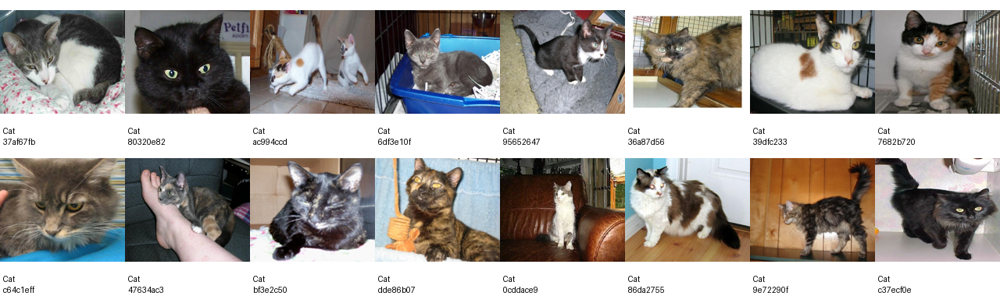

Dog


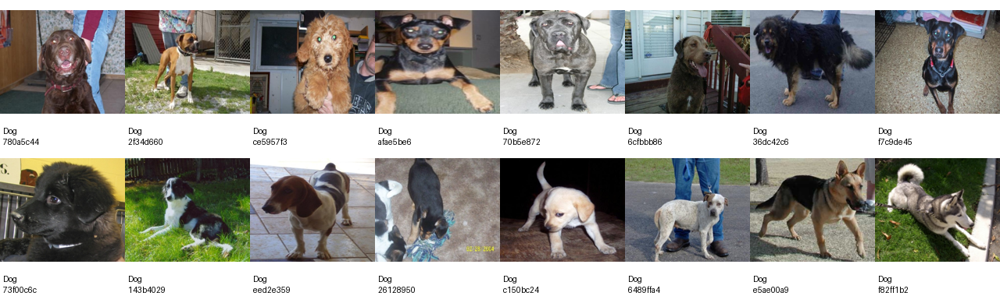

Moris


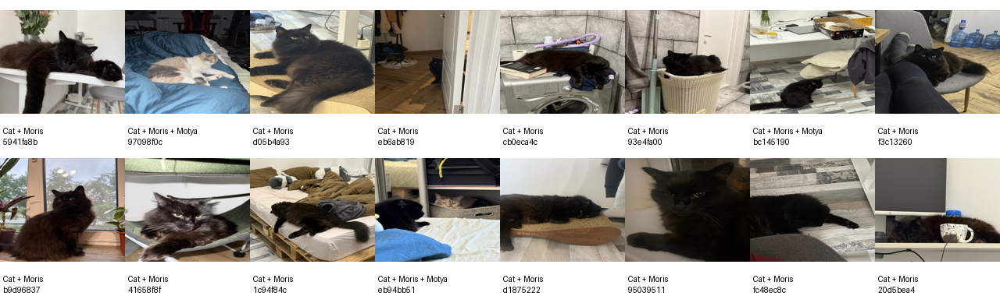

Motya


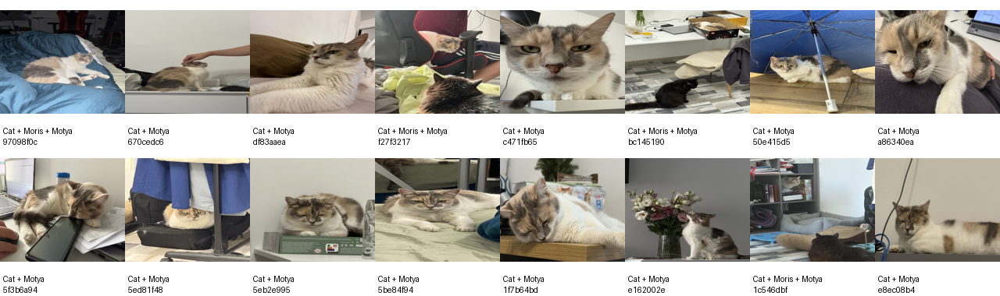

Biatrix


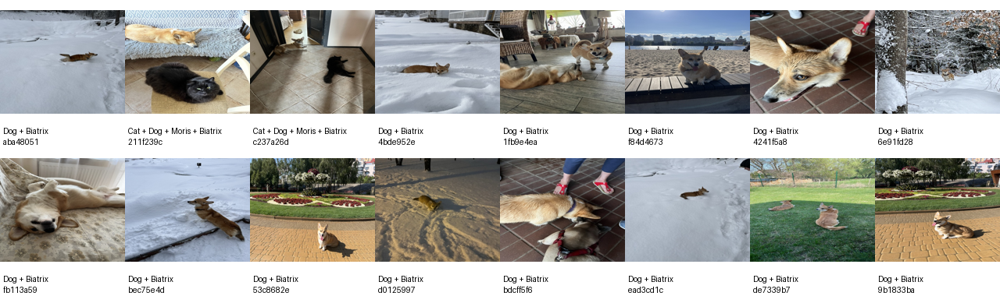

In [144]:
for c in LABELS:
    mask = y[c] == 1
    if c not in NAMED:
        mask &= ~named
    print(c)
    display(grid(train.image_id[mask].sample(16, random_state=0)))

### All named animals
Every photo of Moris, Motya and Biatrix. Look for the same room, background or angle, and for a different animal under the same name.

Moris: 56


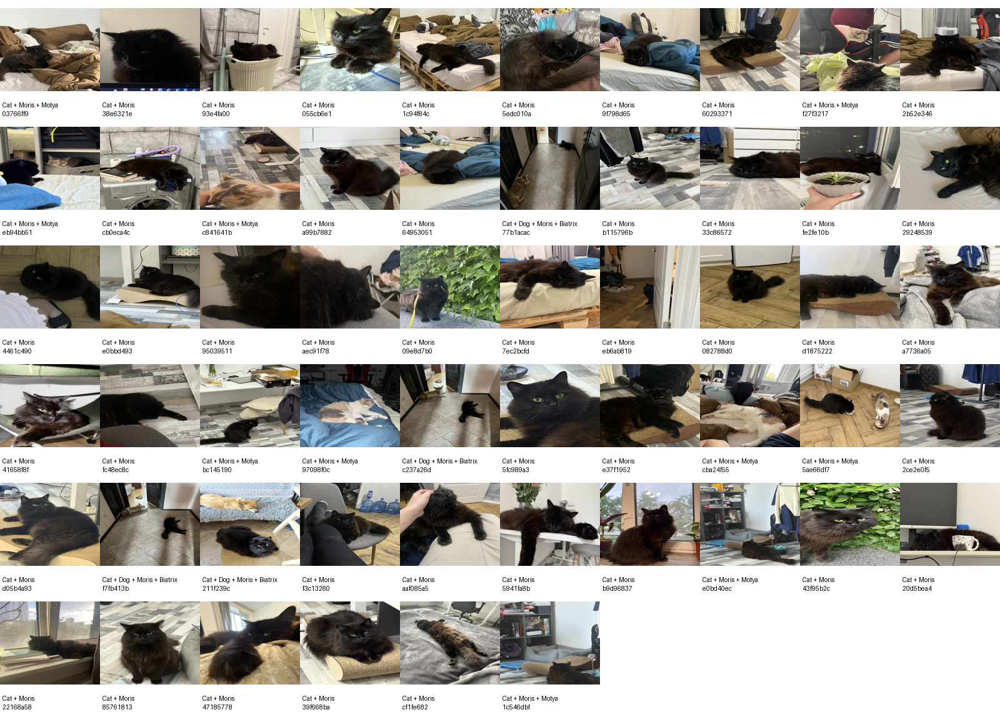

Motya: 42


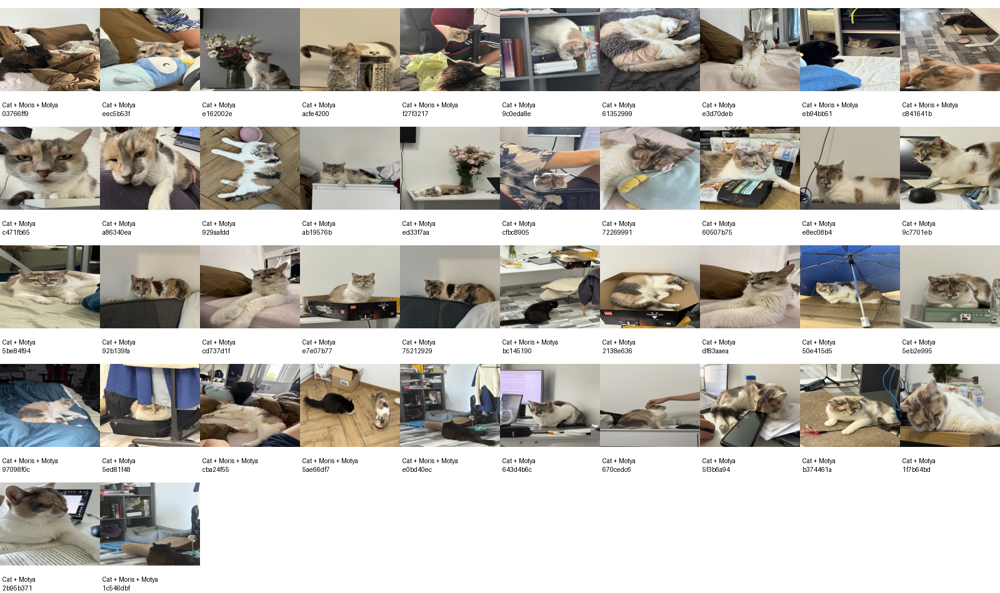

Biatrix: 41


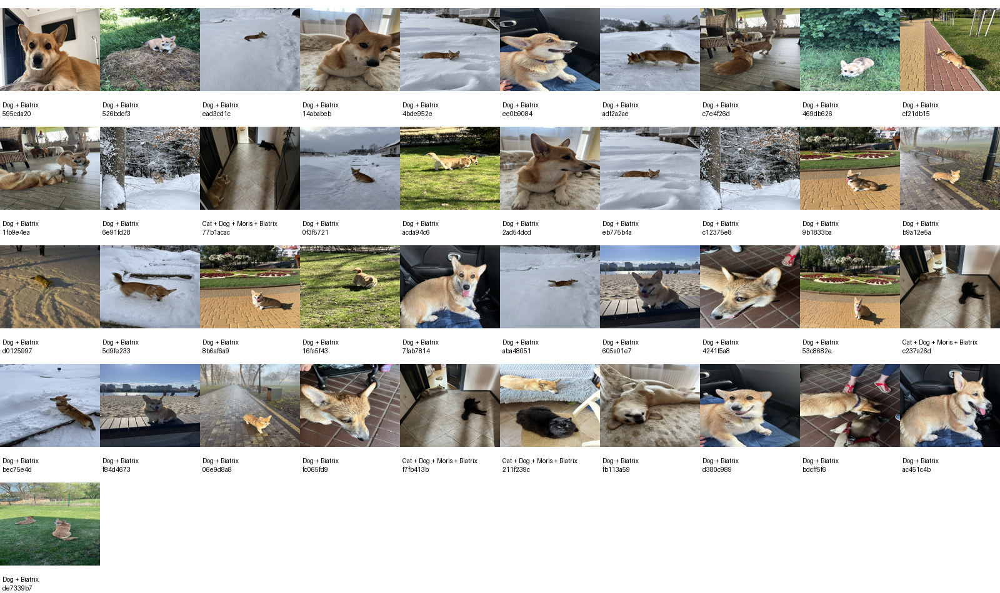

In [145]:
for c in NAMED:
    ids = train.image_id[y[c] == 1]
    print(f"{c}: {len(ids)}")
    display(grid(ids, cols=10))

### Unlabelled images
A random sample of photos without any label: is there really no cat or dog?

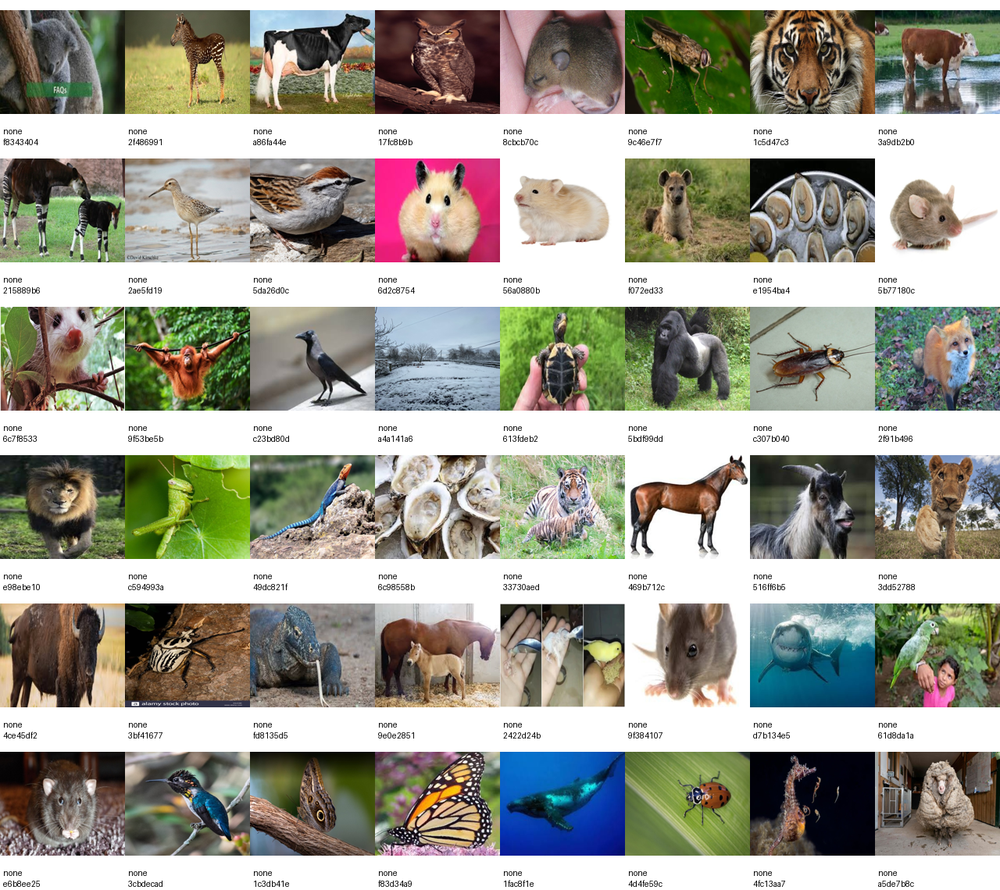

In [146]:
grid(train.image_id[y.sum(axis=1) == 0].sample(48, random_state=0))

### Images with several animals
The csv has no "several animals" flag, so we look at the combinations that imply it.

Cat + Dog: 4


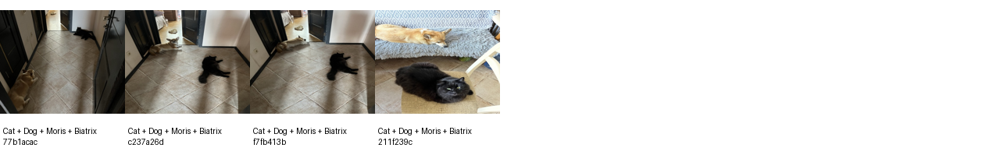

Moris + Motya: 10


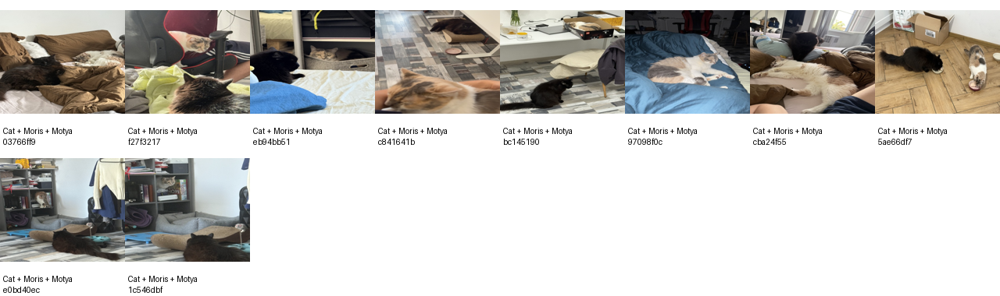

In [147]:
for name, mask in {"Cat + Dog": (y.Cat == 1) & (y.Dog == 1), "Moris + Motya": (y.Moris == 1) & (y.Motya == 1)}.items():
    print(f"{name}: {mask.sum()}")
    display(grid(train.image_id[mask]))

### Visual observations and ideas

Ordinary Cat / Dog examples look like web photos, and many unlabelled examples show other animals. Moris and Motya often share indoor backgrounds; Biatrix also appears outdoors and in a car. Poses, angles and the animal's size in the frame vary. A single `Cat` label can cover several cats on one image.

So, we can try:
- Augmentation for the rare classes:
  - `RandomResizedCrop` for scale and framing, carefully: a crop can remove a labelled animal;
  - horizontal flip and a slight rotation for pose variation;
  - JPEG compression, blur, downscale → upscale for image quality variation;
  - mild brightness and contrast jitter for lighting variation. Keep grayscale and hue shifts out of the first experiments, since coat colour may help distinguish the named animals.
- A separate decision threshold for each class. Keep it if the gain over one shared threshold holds on data not used to choose the thresholds.
- A label hierarchy: if the model predicts Moris or Motya, also set `Cat`; if it predicts Biatrix, also set `Dog`. The train labels support this rule, but a wrong identity prediction can also spread to the species label; compare held-out F1 with and without it.
- Repeated backgrounds may become a shortcut. Use Grad-CAM as a clue, then check errors on held-out photos with different backgrounds: a drop there would support this concern more than a heatmap alone.
- Look for false positives on other black cats, foxes and ginger dogs.

## 4. Duplicates

### Exact duplicates

In [148]:
def span(splits) -> str:
    """Splits a pair or group covers: 'train', 'test' or 'train + test'."""
    return " + ".join(sorted(set(splits), reverse=True))


def duplicates(key: str) -> pd.Series:
    """Groups of 2+ images sharing `key`: count per split span, largest group, test images in groups containing train, label mix-ups."""
    dup = images[images[key].duplicated(keep=False)].merge(train, on="image_id", how="left")
    spans = dup.groupby(key).split.agg(span)
    return pd.Series({
        **spans.value_counts().add_prefix("groups in ").to_dict(),
        "largest group": dup[key].value_counts().max(),
        "test images in groups containing train": (dup.split.eq("test") & dup[key].isin(spans.index[spans == "train + test"])).sum(),
        "train groups with different labels": dup[dup.split == "train"].groupby(key)[LABELS].nunique().gt(1).any(axis=1).sum(),
    }, name=key)


paths = [image_path(s, i) for s, i in zip(images.split, images.image_id)]
images = images.assign(md5=[hashlib.md5(p.read_bytes()).hexdigest() for p in paths])
duplicates("md5")

groups in train + test                    14
groups in test                            12
groups in train                            5
largest group                              2
test images in groups containing train    14
train groups with different labels         0
Name: md5, dtype: int64

### Near duplicates
pHash of every image; every pair within Hamming distance 12.

In [149]:
DCT = np.cos(np.pi * np.outer(np.arange(32), np.arange(32) * 2 + 1) / 64)  # 32-point DCT-II basis


def phash(path: Path) -> int:
    """64-bit perceptual hash: 32x32 grayscale -> 2D DCT -> the 8x8 lowest frequencies above their median."""
    with Image.open(path) as im:
        px = np.asarray(im.convert("L").resize((32, 32), Image.Resampling.LANCZOS), dtype=float)
    low = (DCT @ px @ DCT.T)[:8, :8]
    return int.from_bytes(np.packbits(low > np.median(low)).tobytes(), "big")


H = np.array([phash(p) for p in tqdm(paths, desc="pHash")], dtype=np.uint64)

chunks = []
for s in range(0, len(H), 1024):
    d = np.bitwise_count(H[s:s + 1024, None] ^ H)
    a, b = np.nonzero(np.triu(d <= 12, k=s + 1))  # each pair once: column > row
    chunks.append(pd.DataFrame({"a": a + s, "b": b, "d": d[a, b]}))
pairs = pd.concat(chunks, ignore_index=True)

split = images.split.to_numpy()
Y = images[["image_id"]].merge(train, how="left")[LABELS].to_numpy()
pairs["span"] = [span((split[a], split[b])) for a, b in zip(pairs.a, pairs.b)]
pairs["different labels"] = (pairs.span == "train") & (Y[pairs.a] != Y[pairs.b]).any(axis=1)
pd.crosstab(pairs.d, pairs.span).assign(**{"train, different labels": pairs.groupby("d")["different labels"].sum()})

pHash:   0%|          | 0/30933 [00:00<?, ?it/s]

span,test,train,train + test,"train, different labels"
d,,,,
0,240,124,353,0
2,62,38,77,0
4,4,0,6,0
6,4,1,2,0
8,9,7,23,3
10,96,41,123,19
12,875,384,1141,218


### Threshold comparison
Count each pair once. A test image has a direct train candidate only if there is a train ↔ test edge within the threshold.

In [150]:
threshold_rows = []
for threshold in [2, 4, 6, 8]:
    within = pairs[pairs.d <= threshold]
    cross = within.loc[within.span == "train + test", ["a", "b"]].to_numpy().ravel()
    direct_test = np.unique(cross[split[cross] == "test"])
    threshold_rows.append({
        "pHash ≤": threshold,
        **within.span.value_counts().reindex(["train", "test", "train + test"], fill_value=0).to_dict(),
        "test images with a direct train candidate": len(direct_test),
    })
threshold_counts = pd.DataFrame(threshold_rows).set_index("pHash ≤")
assert (pairs.a < pairs.b).all() and not pairs.duplicated(["a", "b"]).any()
assert threshold_counts.diff().dropna().ge(0).all().all()
assert threshold_counts["test images with a direct train candidate"].le(threshold_counts["train + test"]).all()
threshold_counts

,train,test,train + test,test images with a direct train candidate
pHash ≤,,,,
2,162,302,430,430
4,162,306,436,436
6,163,310,438,438
8,170,319,461,460


### Pairs by distance
Up to 8 random pairs per distance, 4 pairs per row. Which ones look like the same photo, related frames, or unrelated images?

distance 0: 717 pairs


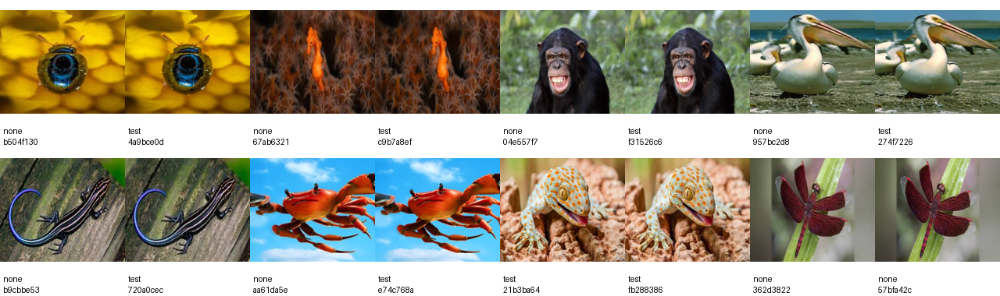

distance 2: 177 pairs


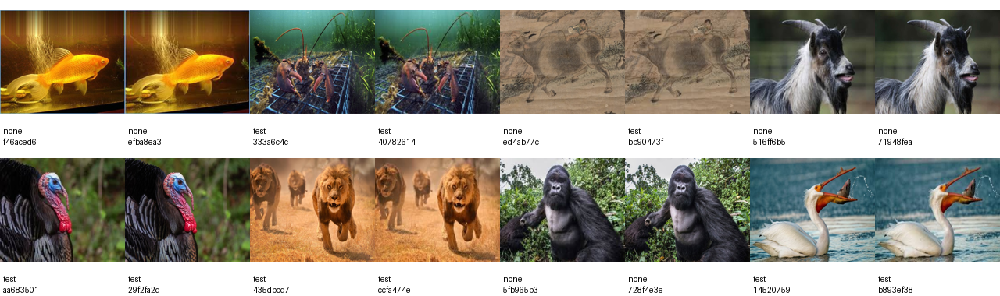

distance 4: 10 pairs


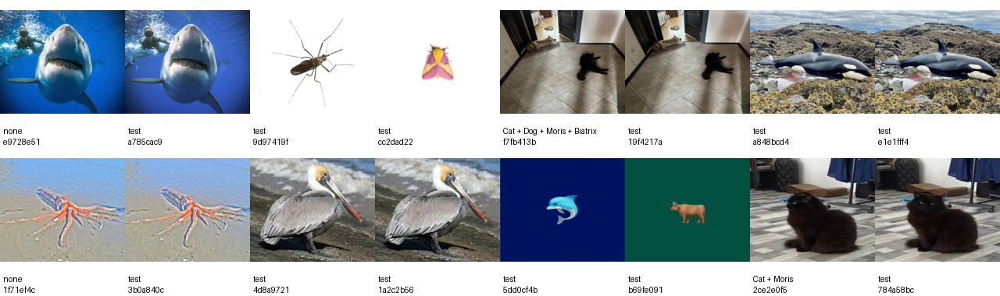

distance 6: 7 pairs


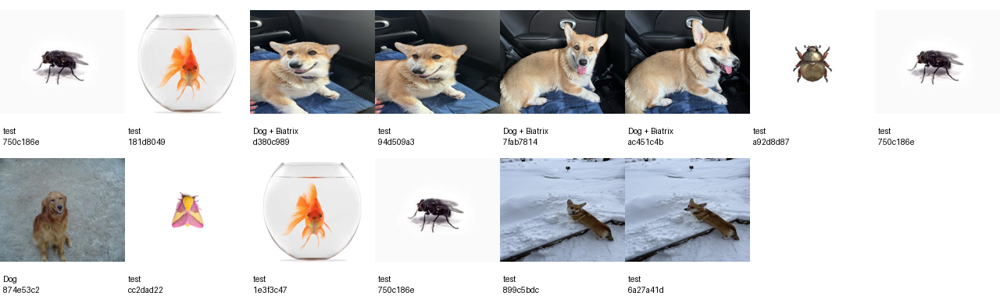

distance 8: 39 pairs


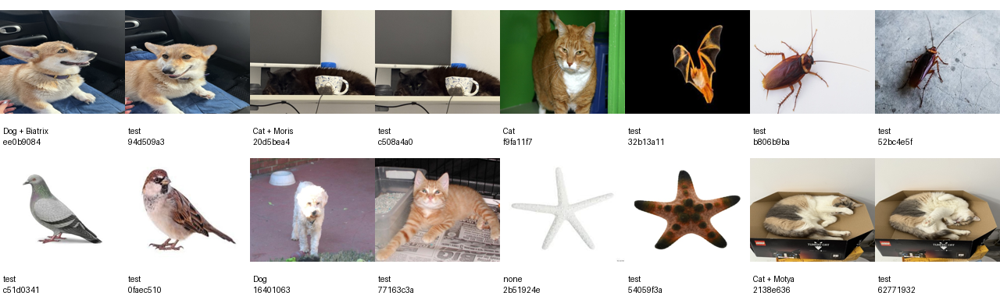

distance 10: 260 pairs


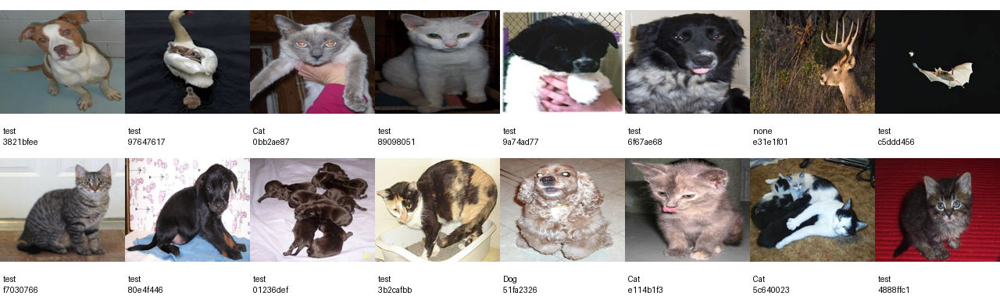

distance 12: 2400 pairs


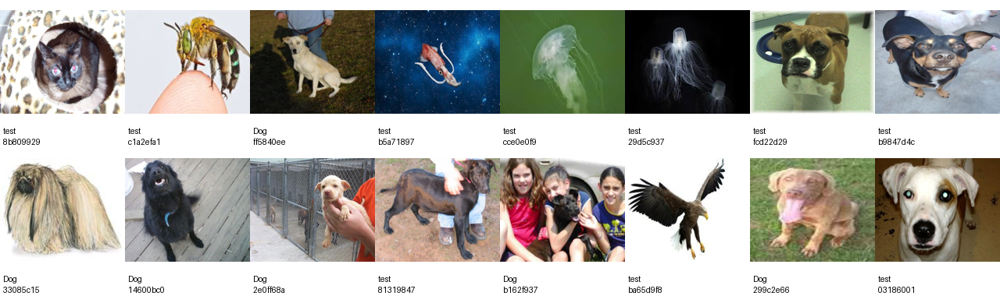

In [151]:
image_ids = images.image_id.to_numpy()
for d, at in pairs.groupby("d"):
    print(f"distance {d}: {len(at)} pairs")
    display(grid(image_ids[at.sample(min(8, len(at)), random_state=0)[["a", "b"]].to_numpy().ravel()]))

### False matches
Distance 6 also joins a dog with a moth, and a beetle with a fly. Similar coarse structure is enough for a pHash collision; the threshold alone cannot confirm a duplicate. These examples do not change the provided labels.

distance 6


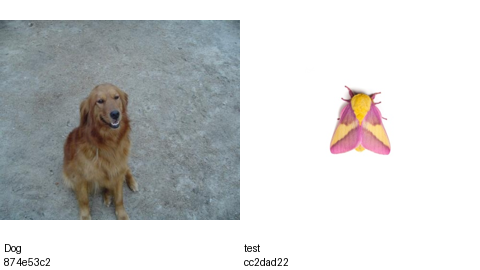

distance 6


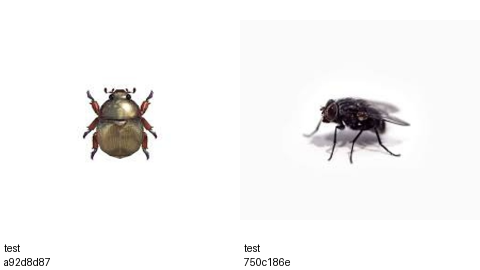

In [152]:
false_pairs = [
    ("874e53c255f67a6f48ac7554f228b72028f9b48e", "cc2dad2210db69c7fa55cc2b4e215897d5489154"),
    ("a92d8d8723d69d7ccd2e3876e472819edc3162d1", "750c186eb414fdf7af6697f45114da3ce155ae41"),
]
for left, right in false_pairs:
    a, b = images.index[images.image_id.isin([left, right])]
    distance = int(H[a] ^ H[b]).bit_count()
    assert distance == 6
    print(f"distance {distance}")
    display(grid([left, right], cols=2, size=240))

### Groups
Connected components at distance ≤6. A direct match is one edge; a group can join images through intermediate photos, so not every pair in it has distance ≤6.

In [153]:
THRESHOLD = 6

a, b = pairs.loc[pairs.d <= THRESHOLD, ["a", "b"]].to_numpy().T
group = np.arange(len(images))
while True:  # connected components: push the smallest index through every edge until nothing changes
    before = group.copy()
    np.minimum.at(group, a, group[b])
    np.minimum.at(group, b, group[a])
    if (group == before).all():
        break
images = images.assign(group=group)
duplicates("group")

groups in train + test                    438
groups in test                            306
groups in train                           163
largest group                               4
test images in groups containing train    439
train groups with different labels          0
Name: group, dtype: int64

In [154]:
train_groups = images.loc[images.split == "train", "group"]
test_in_train_groups = images.loc[(images.split == "test") & images.group.isin(train_groups)]
direct_count = threshold_counts.loc[THRESHOLD, "test images with a direct train candidate"]
assert len(test_in_train_groups) >= direct_count
pd.Series({
    "test images with a direct train candidate": direct_count,
    "test images in a component containing train": len(test_in_train_groups),
    "test images connected only through other photos": len(test_in_train_groups) - direct_count,
})

test images with a direct train candidate          438
test images in a component containing train        439
test images connected only through other photos      1
dtype: int64

### Named animals
How many groups the photos of each named animal split into, and how many test images sit in those groups.

In [155]:
labelled = images.merge(train, on="image_id")
test_per_group = images.group[images.split == "test"].value_counts()


def named_groups(c: str) -> dict:
    g = labelled.group[labelled[c] == 1]
    return {"photos": len(g), "groups": g.nunique(), "test images in these groups": test_per_group.reindex(g.unique(), fill_value=0).sum()}


pd.DataFrame({c: named_groups(c) for c in NAMED}).T

,photos,groups,test images in these groups
Moris,56,56,4
Motya,42,42,1
Biatrix,41,39,5


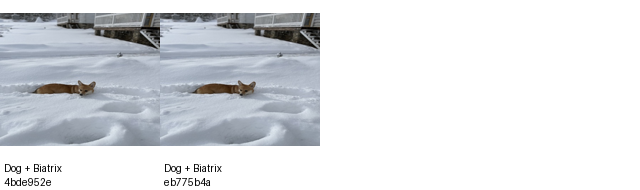

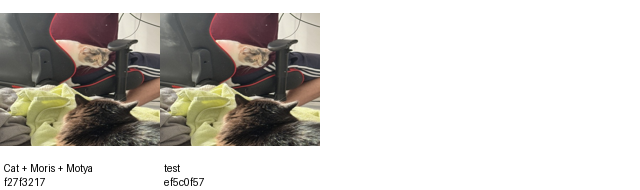

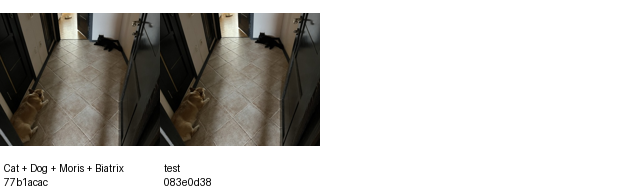

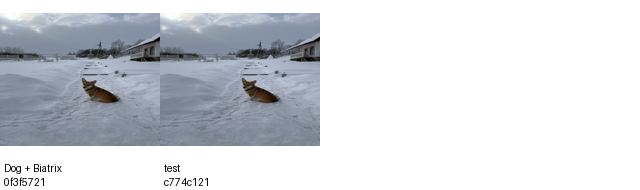

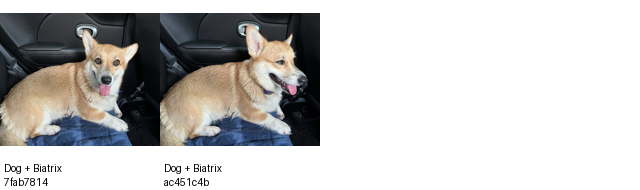

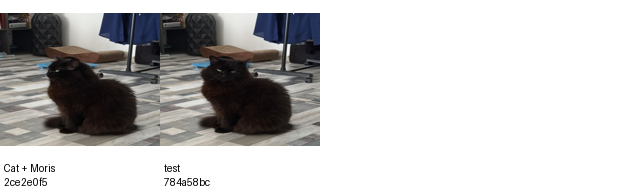

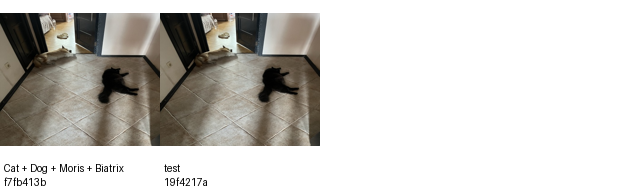

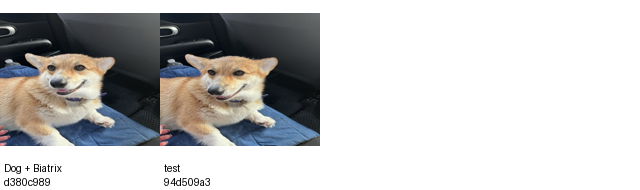

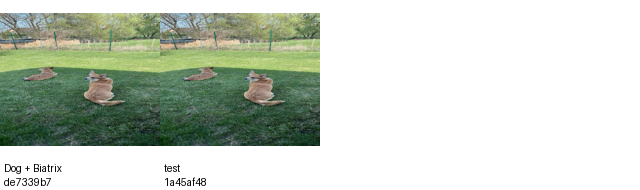

In [156]:
named_group_ids = set(labelled.group[labelled[NAMED].any(axis=1)])
for _, members in images[images.group.isin(named_group_ids) & images.group.duplicated(keep=False)].groupby("group").image_id:
    display(grid(members, cols=4))

Exact copies are rare: 31 pairs, 14 of them train ↔ test. At pHash distance ≤6, 438 test images have a direct train candidate; 439  belong to a component containing train. The extra image is connected through another photo.
Moris, Motya and Biatrix span 56 / 42 / 39 train groups. Seven unique test images share components with named-animal photos (the per-class counts overlap). 

Split train with StratifiedGroupKFold by `group` so near-duplicates stay in one fold.


On top of the model we can try an optional similarity layer that refines the answer using near-identical train photos.

If a test image has a train match at pHash ≤2, use p = (1 − λ)·p_model + λ·y_train; otherwise keep p_model. Distances 4–6 give weaker candidates, and the false matches above show that pHash alone does not confirm a copy.

Evaluate the model with StratifiedGroupKFold by `group`. Tune λ on a random split, where pairs cross folds the same way they cross train ↔ test. Exact test-only copies can share the model's probabilities. As a final check, submit with and without the layer.


## 5. Train vs test

### File size

In [157]:
images = images.assign(kb=images.bytes / 1024)
images.groupby("split")[["kb"]].describe().T.round(2)[list(splits)]

split        train      test
kb count  12260.00  18673.00
   mean      56.99     56.89
   std       16.08     16.40
   min        7.51      3.33
   25%       45.95     45.77
   50%       54.51     54.30
   75%       65.52     65.35
   max      145.02    140.40

### File size distribution


In [158]:
buckets = pd.cut(images.kb, range(0, int(images.kb.max()) + 10, 10))
pd.crosstab(buckets, images.split, normalize="columns").round(3)[list(splits)]

split,train,test
kb,,
"(0, 10]",0.000,0.000
"(10, 20]",0.003,0.002
"(20, 30]",0.015,0.017
"(30, 40]",0.094,0.101
"(40, 50]",0.252,0.254
"(50, 60]",0.275,0.272
"(60, 70]",0.174,0.170
"(70, 80]",0.096,0.091
"(80, 90]",0.050,0.050


Both sets are RGB JPEGs at 450 × 375 with no EXIF, and their file sizes overlap. 

### Random samples
32 images per split, sampled with the same fixed seed.

train


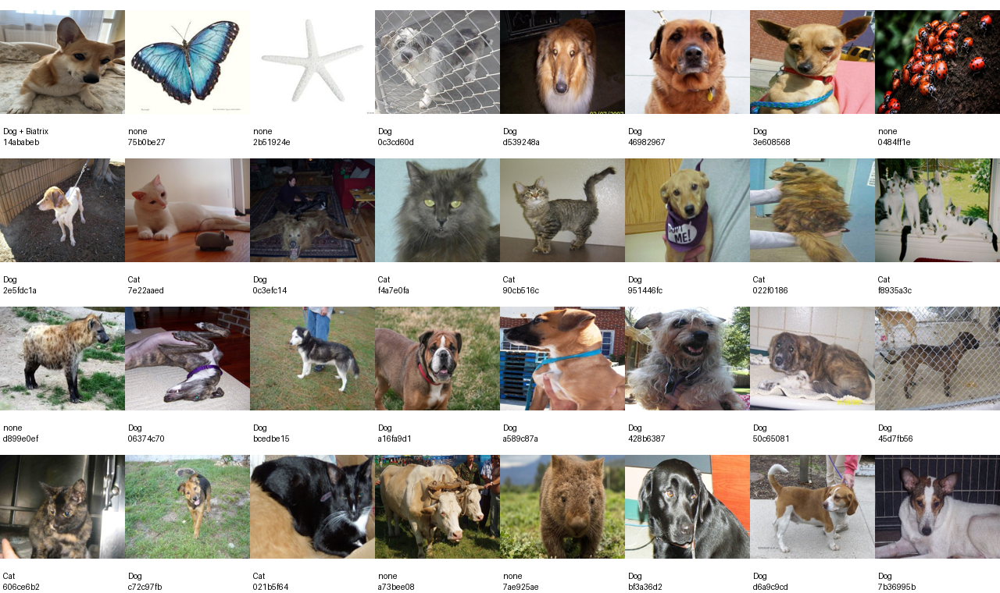

test


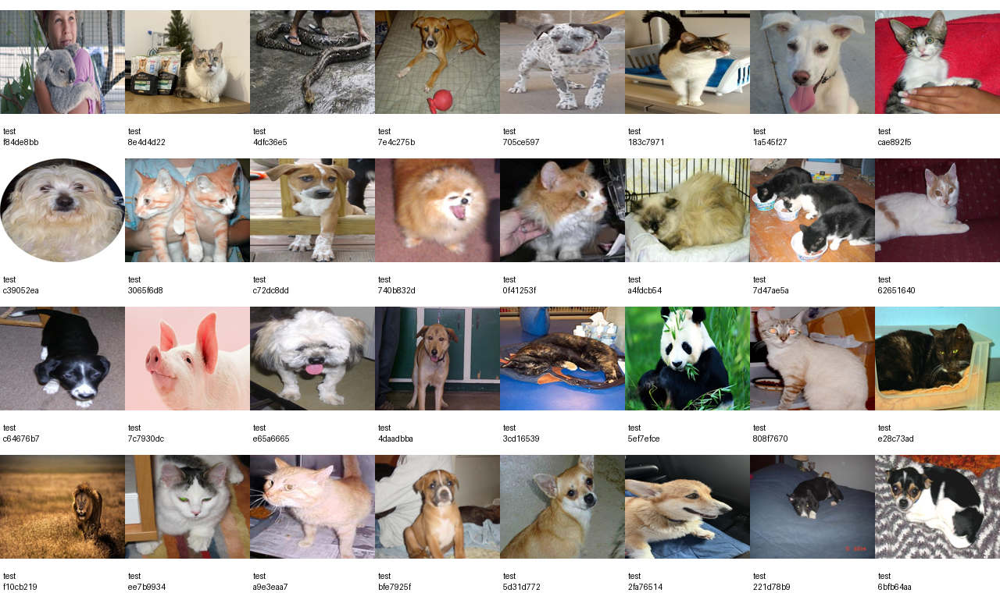

In [159]:
sample_ids = {split: df.image_id.sample(32, random_state=0) for split, df in splits.items()}
for name, ids in sample_ids.items():
    print(name)
    display(grid(ids))

### Brightness and contrast
Per-image mean and standard deviation of grayscale pixels scaled to [0, 1]. Quantiles across images, not pooled pixels.

In [160]:
light_quantiles = images.groupby("split")[["brightness", "contrast"]].quantile([.05, .25, .5, .75, .95])
light_quantiles.index.names = ["split", "quantile"]
light_quantiles.unstack("split").reindex(columns=pd.MultiIndex.from_product([["brightness", "contrast"], list(splits)])).round(3)

brightness        contrast       
              train   test    train   test
quantile                                  
0.05          0.278  0.280    0.131  0.132
0.25          0.390  0.391    0.180  0.181
0.50          0.462  0.464    0.216  0.216
0.75          0.534  0.534    0.253  0.253
0.95          0.670  0.668    0.311  0.310

No visible shift between train and test: same scene types in the random samples, median brightness 0.462 vs 0.464, contrast 0.216 in both. Brightness varies 0.28–0.67 within each set, so mild brightness/contrast jitter is worth trying.